# Lab 01: How to call a model and read the response

## Goal

Send one message list to the Chat Completions API, read every field of the response, and turn its usage into
dollars. Two moments teach it. A call that finishes without any error can hand back half a sentence, and only
`finish_reason: "length"` says so. And a second call has forgotten the order number we gave the first one, until our
code sends the history itself.

## What you will learn

- How to build a message list with `system` and `user` roles and send it with `client.chat.completions.create`.
- How to read a `ChatCompletion` field by field (`choices`, `message`, `finish_reason`, `usage`) and say what each
  field is for.
- What a token is, and how to price a call from `models.env`, including cached input and cache writes.
- Why the API keeps no memory between calls, and how sending the history makes a conversation.
- How to stream a reply and read its usage from the last chunk.
- How the same call looks on the Responses API, and why these labs start on Chat Completions.

**Run first:** Lab 00, so you know the environment and the key work.

⚠️ Every cell that calls the model spends a little money on your key. This notebook makes about twenty short calls;
together they cost well under one US cent at the prices in `models.env`.

## Setup

The first cell is the same in every lab of this repo (Lab 00 explains it line by line). It finds the repository
folder, reads the model name, the reasoning effort and the prices from `models.env`, takes the key from `.env`, and
prints what it found, never the key itself. This lab adds two imports to it: `json`, to print the response in a
readable shape, and from the `openai` package the client, one of its error classes and `omit`.

In [1]:
from pathlib import Path
import os
import json
from dotenv import dotenv_values
from openai import OpenAI, BadRequestError, omit

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


`MODEL` and `EFFORT` are the two settings every call below uses, so no model name appears in the code: change
`MODEL_DEFAULT` in `models.env` and every cell follows.

Next, the client. `OpenAI()` reads `OPENAI_API_KEY` from the environment by itself, so we never pass the key in or
print it. The client knows the key and the address of the API; it sends nothing until we call one of its methods.

In [2]:
client = OpenAI()
print(type(client).__name__, "| sends requests to", client.base_url)

OpenAI | sends requests to https://api.openai.com/v1/


## Part A: Send a message list and read the response

Every agent in this repo, with or without a framework, is built from one operation: our code sends a list of
messages to a model and gets one reply back. Before any tools or loops, we look at that one call closely: what we
send, and every field of what comes back.

### The message list

A message is a Python dict with two keys, `role` and `content`. Three roles appear in these labs:

- `system`: the standing instruction, such as who the assistant is and how long its answers should be. The API does
  not store it: it applies to this call only.
- `user`: the request for this turn.
- `assistant`: a reply the model gave earlier. We send it back ourselves in Part D.

The list is ordered: the system message first, then the turns in the order they happened. Our first list holds two
messages, the shop's instruction and a customer's question.

In [3]:
# SYSTEM: the shop's standing instruction; QUESTION: this turn's request; messages: the list we send, in order
SYSTEM = {
    "role": "system",
    "content": "You are a support assistant for the Chinook music shop. Answer in one or two short sentences.",
}
QUESTION = {"role": "user", "content": "What is a support ticket?"}
messages = [SYSTEM, QUESTION]

for message in messages:
    print(f'{message["role"]:>6}: {message["content"]}')

system: You are a support assistant for the Chinook music shop. Answer in one or two short sentences.
  user: What is a support ticket?


Two dicts, in order. (`:>6` in the f-string right-aligns each role in six characters, so the lines line up.) That
list is the whole input to the call: the model sees nothing else, no earlier cell, no file and no previous call.

### One call to `chat.completions.create`

The arguments, one by one:

- `model=MODEL`: the model name from `models.env`.
- `messages=messages`: the list above.
- `reasoning_effort=EFFORT or omit`: how much hidden thinking the model may do before it answers. `models.env` sets
  `none`; Part B shows why. `omit` tells the `openai` package to leave the argument out of the request, so the call
  still works when `REASONING_EFFORT` is empty in `models.env` (`EFFORT` is then `None`, for a model without
  reasoning).
- `max_completion_tokens=200`: the most the reply may use, counted in tokens. A token is a piece of text, often a
  short word or part of a longer one; Part C counts them. 200 is our teaching choice, room for two short sentences.
  It is a ceiling, not a target.

In [4]:
response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=200,
)
print(response.choices[0].message.content)

A support ticket is a request that records a customer’s question or problem so the support team can track and respond to it.


That is the answer we asked for, in one or two short sentences as the system message said. But `response` itself is
not a string; the text we printed is one field, a few levels down. Here is the type of `response` and the whole
object.

`model_dump()` turns the SDK's object into plain Python dicts and lists. `exclude_none=True` leaves out the fields
that are empty (`None`) on this call, so the dump stays short. `json.dumps(..., indent=2)` prints it one field per
line.

In [5]:
print(type(response))
print(json.dumps(response.model_dump(exclude_none=True), indent=2))

<class 'openai.types.chat.chat_completion.ChatCompletion'>
{
  "id": "chatcmpl-EfsiFUuoKus0lwnjfaIGs6rll8BdW",
  "choices": [
    {
      "finish_reason": "stop",
      "index": 0,
      "message": {
        "content": "A support ticket is a request that records a customer\u2019s question or problem so the support team can track and respond to it.",
        "role": "assistant",
        "annotations": []
      }
    }
  ],
  "created": 1793650471,
  "model": "gpt-6-luna",
  "object": "chat.completion",
  "service_tier": "default",
  "usage": {
    "completion_tokens": 28,
    "prompt_tokens": 36,
    "total_tokens": 64,
    "completion_tokens_details": {
      "accepted_prediction_tokens": 0,
      "audio_tokens": 0,
      "reasoning_tokens": 0,
      "rejected_prediction_tokens": 0
    },
    "prompt_tokens_details": {
      "audio_tokens": 0,
      "cache_write_tokens": 0,
      "cached_tokens": 0
    }
  }
}


A `ChatCompletion`, read field by field. The values in the middle column come from the run above.

| Field | In this run | What it holds |
|---|---|---|
| `id` | `chatcmpl-...` | The call's id, for logs and traces |
| `model` | `gpt-6-luna` | The model that answered |
| `choices` | a list of 1 | The replies. The API can return several (`n=2`); we always read `choices[0]` |
| `choices[0].message.role` | `assistant` | Who wrote it. In Part D this whole message goes back into the list |
| `choices[0].message.content` | the text | The reply |
| `choices[0].finish_reason` | `stop` | Why the reply ended: Part B |
| `usage.prompt_tokens` | 36 | Tokens we sent: Part C |
| `usage.completion_tokens` | 28 | Tokens the model wrote: Part C |
| `usage.total_tokens` | 64 | The two added together |
| `usage.completion_tokens_details.reasoning_tokens` | 0 | Hidden thinking tokens, part of `completion_tokens`: Part B |
| `usage.prompt_tokens_details.cached_tokens` and `cache_write_tokens` | 0 and 0 | Prompt caching: Part C |

One field is missing from the dump because it is `None` on this call: `message.tool_calls`. When a model asks for a
tool (lab 03), that field holds the request and `content` may be empty. The object keeps the same shape.

In [6]:
print("tool_calls:", response.choices[0].message.tool_calls)

tool_calls: None


### Read the fields in code

Later labs read these fields in code, not in a dump. Two names make that shorter: `choice` for the first reply and
`usage` for the token counts of the whole call.

In [7]:
# choice: the first (and only) reply; usage: the token counts for the whole call
choice = response.choices[0]
usage = response.usage

print("finish_reason:    ", choice.finish_reason)
print("role:             ", choice.message.role)
print("prompt_tokens:    ", usage.prompt_tokens)
print("completion_tokens:", usage.completion_tokens)
print("total_tokens:     ", usage.total_tokens)

finish_reason:     stop
role:              assistant
prompt_tokens:     36
completion_tokens: 28
total_tokens:      64


`total_tokens` is `prompt_tokens` plus `completion_tokens`: 36 + 28 = 64. The prompt
is 36 tokens for a one-line instruction and a five-word question; Part C shows where they come from.

**Checkpoint A.** `finish_reason` is `stop`; `prompt_tokens` is 36 and `completion_tokens` around 25 to 50
(ours: 28); `reasoning_tokens` is 0; `tool_calls` is `None`. The wording of the reply changes from run to
run.

## Part B: Read why a call stopped

A reply can look complete on screen and still be cut off, and the call raises no error when that happens.
`finish_reason` is the field that says why the reply ended. So far we have seen `stop`: the model finished on its own.
Now we give it less room.

Predict before you run: the full answer above used 28 tokens. What comes back when the budget is 20?

In [8]:
short = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=20,
)
print("finish_reason:    ", short.choices[0].finish_reason)
print("completion_tokens:", short.usage.completion_tokens)
print("content:          ", short.choices[0].message.content)

finish_reason:     length
completion_tokens: 20
content:           A support ticket is a request for help or a report of an issue, recorded so


`length`, exactly 20 tokens, and the text stops in the middle of a sentence ("...an issue, recorded so"). There was no exception and no warning: if our code only printed `content`, a customer would see
half an answer. We sent this call fourteen times in all. Every one stopped at 20 tokens with `length`; thirteen broke
off mid-sentence, and once the 20 tokens happened to end on a full stop (*"A support ticket is a record of a question
or problem you send to customer support."*), so the reply looked finished. The full answer took 28 to 50 tokens in
nine runs, so 20 is always too few for this question, and only `finish_reason` tells us.

**How do we notice it in code?** We check `finish_reason` before we trust a reply. Here is the check on both calls so
far.

In [9]:
for name, reply in [("200-token budget", response), ("20-token budget", short)]:
    if reply.choices[0].finish_reason == "length":
        print(f"❌ {name}: cut off at {reply.usage.completion_tokens} tokens")
    else:
        print(f"✅ {name}: finished on its own ({reply.choices[0].finish_reason})")

✅ 200-token budget: finished on its own (stop)
❌ 20-token budget: cut off at 20 tokens


A pass says the model ended the reply itself. It does not say the reply is right. Every later lab that shows a reply
can run this check first; a framework that hides the field still receives it.

### Why these labs set reasoning effort to none

Models like this one can think before they answer: they write hidden **reasoning tokens** that we never see in
`content`. `reasoning_effort` sets how much thinking is allowed (`none`, `low`, `medium` and higher). Reasoning
tokens are part of `completion_tokens`, so they count against `max_completion_tokens` and are billed as output.

We try the same question at effort `low`, once with 20 tokens and once with 200. If
`REASONING_EFFORT` is empty, the model has no reasoning setting, so this experiment prints a skip message. `!r` in the f-string prints the content
with its quotes, so an empty reply shows as `''` instead of nothing:

In [10]:
if EFFORT is None:
    print("Reasoning setting is empty; skip the low-effort experiment.")
else:
    for budget in [20, 200]:
        thought = client.chat.completions.create(
            model=MODEL,
            messages=messages,
            reasoning_effort="low",
            max_completion_tokens=budget,
        )
        details = thought.usage.completion_tokens_details
        print(f"budget {budget}: finish_reason={thought.choices[0].finish_reason}, "
              f"reasoning_tokens={details.reasoning_tokens}, content={thought.choices[0].message.content!r}")

budget 20: finish_reason=length, reasoning_tokens=20, content=''


budget 200: finish_reason=stop, reasoning_tokens=0, content='A support ticket is a record of a customer’s question or problem that the support team can track and resolve.'


With 20 tokens the reply is empty: `finish_reason` is `length` and all 20 tokens went to reasoning, so nothing was
left for the answer. With 200 tokens the same effort used 0 reasoning tokens on this easy question. The
model decides how much to think within the effort we allow; code cannot predict it, so it reads `reasoning_tokens`.
In our runs the 20-token call came back empty ten times out of ten, and the 200-token call used no reasoning in
eight of eight. An empty `content` with `length` is the second face of the same dead end: the budget ran out before the
answer started.

### A request the API refuses: effort `low` with a tool

The bigger reason for `none` comes in lab 03, where the model asks our code to run **tools** (functions it can
request by name). On Chat Completions this model accepts tools only at effort `none`. We send the smallest possible
tool at effort `low` to see the API's answer. The tool's format is lab 03's subject; here it only needs a name, a
description and no arguments.

`BadRequestError` is the error the `openai` package raises for a 400 response (a request the API refuses). `try` /
`except` catches it, so we can read the error object instead of stopping the notebook: `status_code` is the HTTP status
and `body` the API's own explanation.

In [11]:
# A tool with a name, a description and no arguments: enough to see whether the API accepts the request
clock = {
    "type": "function",
    "function": {"name": "get_time", "description": "The current time.", "parameters": {"type": "object", "properties": {}}},
}

try:
    client.chat.completions.create(
        model=MODEL,
        messages=messages,
        tools=[clock],
        reasoning_effort="low",
        max_completion_tokens=20,
    )
except BadRequestError as error:
    print("status:", error.status_code)
    print("param: ", error.body["param"])
    print("message:", error.body["message"])

status: 400
param:  reasoning_effort
message: Function tools with reasoning_effort are not supported for gpt-6-luna in /v1/chat/completions. To use function tools, use /v1/responses or set reasoning_effort to 'none'.


The API refused the request before the model ran, and its message names both ways out: set the effort to `none`, or
use `/v1/responses`, the Responses API of Part F. That is why `models.env` sets `REASONING_EFFORT=none` for labs 01 to
06, which send tools on Chat Completions.

Two more settings this model refuses, read the same way. `max_tokens` is the older name for the reply budget, and
`temperature` (how random the wording is) only works at effort `none`. The `**extra` in the call unpacks a dict into
keyword arguments, so each request below is the Part A call plus one or two changed settings. If you switch
`models.env` to another model, the `else` branch reports a request that model accepts.

In [12]:
# Each entry: what we try, and the settings added to the Part A call
refused = [
    ("max_tokens instead of max_completion_tokens", {"max_tokens": 20, "reasoning_effort": EFFORT or omit}),
    ("temperature at effort low", {"temperature": 0.2, "reasoning_effort": "low", "max_completion_tokens": 20}),
]

for label, extra in refused:
    try:
        client.chat.completions.create(model=MODEL, messages=messages, **extra)
    except BadRequestError as error:
        print(f"{label}: {error.status_code} {error.body['message']}")
    else:
        print(f"{label}: accepted by this model")

max_tokens instead of max_completion_tokens: 400 Unsupported parameter: 'max_tokens' is not supported with this model. Use 'max_completion_tokens' instead.


temperature at effort low: 400 Unsupported value: 'temperature' does not support 0.2 with this model. Only the default (1) value is supported.


So a call ends in one of three ways: `stop` (finished), `length` (cut off, or empty when reasoning took the budget),
or a 400 before anything runs. These labs use `max_completion_tokens`, effort `none` from `models.env`, and no
`temperature`.

**Checkpoint B.** At 20 tokens and effort `none`: `length`, 20 completion tokens, half a sentence. At effort `low`:
an empty reply with 20 reasoning tokens. Effort `low` with a tool: a 400 whose message names `/v1/responses` and
`reasoning_effort` `'none'`.

## Part C: Price a call from its usage

Every call is billed by tokens: the tokens we send (input) and the tokens the model writes (output), each at its own
price. An agent makes several calls for one question, so the price of one call, multiplied, is how we tell a cheap
design from an expensive one. First, what we are counting.

### What a token is

A token is the unit the model reads and writes. A common short word is often one token; a longer or rarer word is
several; spaces and punctuation are part of the tokens around them. English text averages about four characters per
token. Rather than trust that rule, we count: three user messages of growing length, each sent alone, and the
`prompt_tokens` the API reports for each. We ignore the replies.

In [13]:
# texts: three user messages of growing length; for each, the characters and the prompt tokens the API counted
texts = [
    "Hello",
    "Hello, I was charged twice for my last order.",
    "Hi, this is Helena. I was charged twice for my order, number 46.",
]
for text in texts:
    counted = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": text}],
        reasoning_effort=EFFORT or omit,
        max_completion_tokens=16,
    )
    print(f"{counted.usage.prompt_tokens:>3} tokens  {len(text):>3} characters  {text!r}")

  7 tokens    5 characters  'Hello'


 17 tokens   45 characters  'Hello, I was charged twice for my last order.'


 24 tokens   64 characters  'Hi, this is Helena. I was charged twice for my order, number 46.'


- **"Hello": 7 tokens for 5 characters.** One word is one token; the rest is the overhead every message
  carries (its role and the markers that separate messages).
- **The longer messages:** 17 and 24 tokens for 45 and 64 characters. The overhead stays the same, so the
  words themselves come to roughly four characters a token, as the rule said.

So Part A's 36 prompt tokens were two messages: the overhead twice, plus the words of the instruction and
the question.

### The prices

`models.env` holds the list prices for the model in `MODEL_DEFAULT`, in US dollars per one million tokens. The config
cell read them into `settings` as text; `float()` turns each into a number.

In [14]:
# Dollars per 1 million tokens, from models.env
PRICE_INPUT = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_CACHED_INPUT = float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
PRICE_CACHE_WRITE = float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
PRICE_OUTPUT = float(settings["PRICE_OUTPUT_PER_MILLION"])

print("input:", PRICE_INPUT, "| cached input:", PRICE_CACHED_INPUT,
      "| cache write:", PRICE_CACHE_WRITE, "| output:", PRICE_OUTPUT)

input: 0.1 | cached input: 0.01 | cache write: 0.125 | output: 0.5


Four prices for one model:

- **Input** (0.10) and **output** (0.50): output tokens cost 5 times as much as input tokens on
  this model.
- **Cached input** (0.01): prompt tokens the API has seen recently and reads back from its cache, at a tenth
  of the input price.
- **Cache write** (0.125): prompt tokens stored in that cache the first time, at 1.25 times the input price.

Caching starts only when a prompt reaches 1,024 tokens, so our short calls report 0 for both (Part A's dump). Lab 05
builds a long prompt and measures the cache. The formula still names them, so it prices long calls correctly too:

$$\text{cost} = \frac{(P - C - W) \times p_{\text{input}} + C \times p_{\text{cached}} + W \times p_{\text{write}} + O \times p_{\text{output}}}{1{,}000{,}000}$$

- $P$ is `prompt_tokens`: every token we sent, cached and written ones included.
- $C$ is `cached_tokens` and $W$ is `cache_write_tokens`. Both are inside $P$, so $P - C - W$ is what is billed at the
  plain input price.
- $O$ is `completion_tokens`, reasoning tokens included.

With Part A's numbers, $P = 36$, $C = 0$, $W = 0$, $O = 28$:

$$\text{cost} = \frac{36 \times 0.10 + 28 \times 0.50}{1{,}000{,}000} = \$0.0000176$$

The same in code, on the `usage` object from Part A (`1_000_000` is one million; Python ignores the underscores).
An optional cache count can be `None`; `or 0` uses zero for an absent count before doing the arithmetic:

In [15]:
details = usage.prompt_tokens_details
cached = details.cached_tokens or 0
written = details.cache_write_tokens or 0
uncached = usage.prompt_tokens - cached - written

cost = (
    uncached * PRICE_INPUT
    + cached * PRICE_CACHED_INPUT
    + written * PRICE_CACHE_WRITE
    + usage.completion_tokens * PRICE_OUTPUT
) / 1_000_000

print(f"uncached input {uncached} | cached {cached} | cache writes {written} "
      f"| output {usage.completion_tokens}")
print(f"this call: ${cost:.7f}")

uncached input 36 | cached 0 | cache writes 0 | output 28
this call: $0.0000176


A small fraction of a cent. One call is not the lesson; the multiplier is. A support desk answers many questions a
day, and an agent makes several calls for each one:

In [16]:
for calls in [1, 1_000, 100_000]:
    print(f"{calls:>7,} calls: ${calls * cost:,.7f}")

      1 calls: $0.0000176
  1,000 calls: $0.0176000
100,000 calls: $1.7600000


At 100,000 calls this short question costs $1.76. A longer prompt, a longer reply or a history that grows with
every turn (Part D) moves that number fast, and `usage` is how we see it before the bill does.

We price more calls below (the stream in Part E, the challenge), so the formula goes into a function now that each
piece has run. `price()` takes a `usage` object like the one above and returns dollars; nothing new happens inside.
One detail: a model without cache-write billing reports `cache_write_tokens` as `None` rather than 0, so `or 0` reads
a missing count as zero.

In [17]:
def price(usage):
    """Dollars for one call, from its usage and the prices in models.env."""
    details = usage.prompt_tokens_details
    cached = details.cached_tokens or 0
    written = details.cache_write_tokens or 0
    uncached = usage.prompt_tokens - cached - written
    return (
        uncached * PRICE_INPUT + cached * PRICE_CACHED_INPUT + written * PRICE_CACHE_WRITE
        + usage.completion_tokens * PRICE_OUTPUT
    ) / 1_000_000


print(f"Part A call: ${price(response.usage):.7f} (the cell above: ${cost:.7f})")
print(f"20-token call: ${price(short.usage):.7f}")

Part A call: $0.0000176 (the cell above: $0.0000176)
20-token call: $0.0000136


The function gives the same dollars as the cell above, so it is the formula and nothing more. The cut-off call cost
less only because it wrote less, and it was useless.

**Checkpoint C.** "Hello" is 7 prompt tokens; the Part A call costs $0.0000176, and 100,000 of them
$1.76; `price(response.usage)` matches the formula cell.

## Part D: Keep a conversation by sending the history

A support chat has more than one turn: the customer says who they are and what went wrong, then asks a follow-up.
Each turn is a new call. Does the second call know what the first one was told?

Turn 1: Helena gives her order number.

In [18]:
# turn_1: the customer's first message; first: the model's reply to it
turn_1 = {"role": "user", "content": "Hi, this is Helena. I was charged twice for my order, number 46."}

first = client.chat.completions.create(
    model=MODEL,
    messages=[SYSTEM, turn_1],
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=200,
)
print(first.choices[0].message.content)

Hi Helena, I’m sorry you were charged twice for order 46. I can’t access billing records here, so please contact Chinook support with the two charge dates and amounts so they can verify and refund any duplicate.


The reply repeats order 46 and says it cannot access billing records. That is the other limit of a single call: the model can only write text. Looking anything up needs a tool, which lab 03 adds.

Turn 2 is a follow-up, sent as a new call with a new list: the system message and the question, as a chat page would
do if it built each request from scratch. Predict: will the reply say 46?

In [19]:
turn_2 = {"role": "user", "content": "What is my order number?"}

second = client.chat.completions.create(
    model=MODEL,
    messages=[SYSTEM, turn_2],
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=200,
)
print(second.choices[0].message.content)
print("prompt_tokens:", second.usage.prompt_tokens)

I don’t have access to your order details. Check your order confirmation email or contact Chinook support with your purchase information.
prompt_tokens: 36


It does not know: it suggests checking the order confirmation email or contacting support instead. In thirteen runs of these two calls, the second never named 46.
Its prompt was 36 tokens: the system message and the question, nothing about Helena. **The API keeps nothing between calls.** The reply to turn 1
lives in our Python variable `first`, not in the model.

The fix is ours to make: we keep the list and send all of it every time. The diagram shows the two calls the next
cells make.

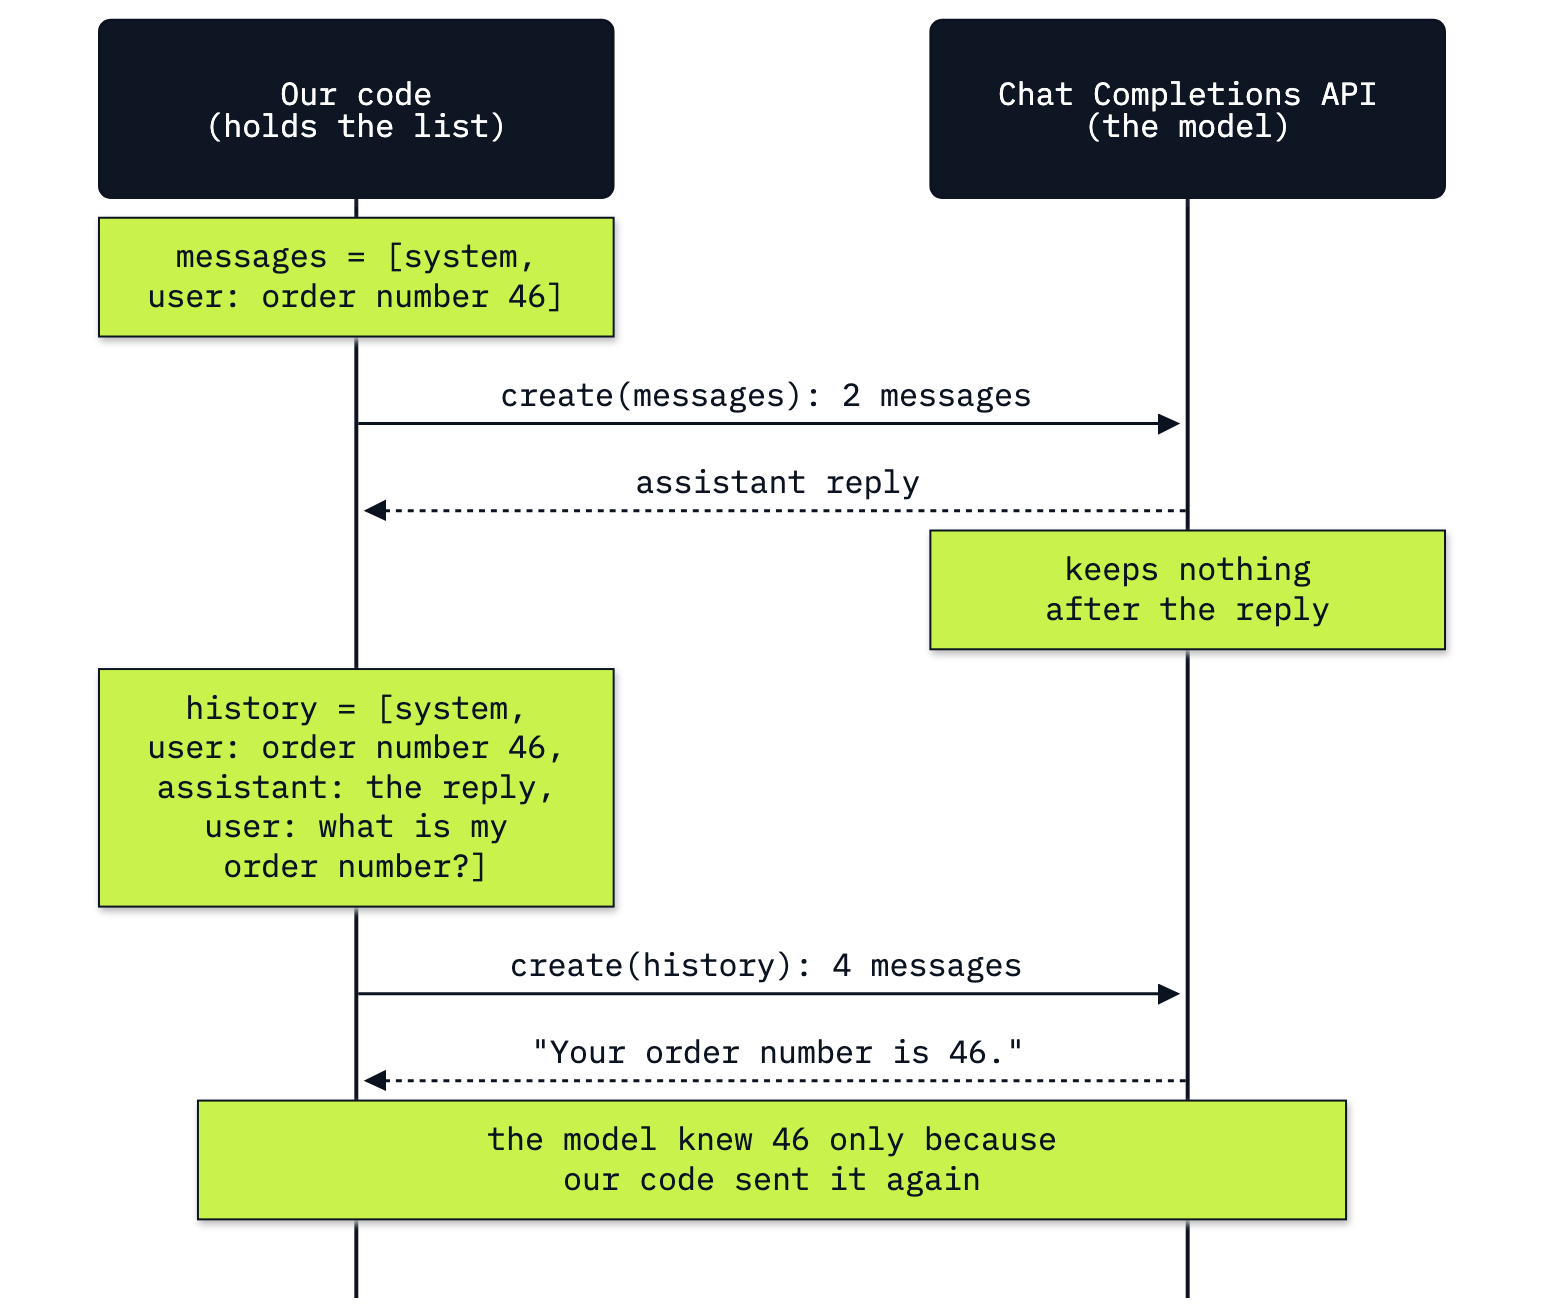

In [20]:
from IPython.display import Image

Image("resources/lab01_message_list.png", width=760)

The history is the same list idea as Part A, longer: the system message, turn 1, the model's own reply as an
`assistant` message, then turn 2, in the order they happened. The print shows the first 80 characters of each
message (`[:80]`).

In [21]:
# history: everything said so far, in order, with the model's reply sent back as an assistant message
history = [
    SYSTEM,
    turn_1,
    {"role": "assistant", "content": first.choices[0].message.content},
    turn_2,
]
for message in history:
    print(f'{message["role"]:>9}: {message["content"][:80]}')

   system: You are a support assistant for the Chinook music shop. Answer in one or two sho
     user: Hi, this is Helena. I was charged twice for my order, number 46.
assistant: Hi Helena, I’m sorry you were charged twice for order 46. I can’t access billing
     user: What is my order number?


Four messages; the third is the text the model wrote in turn 1, which our code now sends back to it. Same model, same
question as the failed call; only the list changes.

In [22]:
remembered = client.chat.completions.create(
    model=MODEL,
    messages=history,
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=200,
)
print(remembered.choices[0].message.content)
print("prompt_tokens:", remembered.usage.prompt_tokens)

Your order number is 46.
prompt_tokens: 109


Now it answers "Your order number is 46." (thirteen of thirteen in our runs). The model did not remember anything: it read 46 in the
list we sent. And the list is billed: 109 prompt tokens against 36 for the call without history. Every turn
resends everything before it, so the prompt, and the price, grows with the conversation.

**Lesson to Remember:** the message list is the conversation's memory, and our code holds it.

| Call | Messages sent | Prompt tokens | Knows the order number? |
|---|---|---|---|
| Turn 2 alone | 2 | 36 | no |
| Turn 2 with the history | 4 | 109 | yes |

Notice that the only difference is what we sent. Labs 02 to 06 build on this list: lab 04's loop appends to it, and
lab 05 measures it and cuts it down.

**Checkpoint D.** The new call does not know the order number; with the history it answers 46, with about 110
prompt tokens instead of 36 (ours: 109).

## Part E: Stream a reply

A customer watching a chat window sees nothing from a normal call until the whole reply is ready. With `stream=True`
the same request comes back in small pieces, as the model writes them. The tokens and the price are the same; only
the timing changes. Chat pages and the frameworks in later labs stream, so we look at one piece first.

`stream` is not a reply. It is an iterator: an object a `for` loop can pull items from, one at a time, as they
arrive. `next(stream)` pulls the first item, a **chunk**.

In [23]:
stream = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=200,
    stream=True,
)
first_chunk = next(stream)

print(type(stream).__name__)
print(json.dumps(first_chunk.model_dump(exclude_none=True), indent=2))

Stream
{
  "id": "chatcmpl-EfsiTGX2XS9Kqe6lheD3WvWYjeaEK",
  "choices": [
    {
      "delta": {
        "content": "",
        "role": "assistant"
      },
      "index": 0
    }
  ],
  "created": 1793650485,
  "model": "gpt-6-luna",
  "object": "chat.completion.chunk",
  "obfuscation": "Qyv0fCpExrXFx",
  "service_tier": "default"
}


A chunk looks like a small `ChatCompletion`, with one difference: `choices[0]` holds a `delta` (the new piece since
the last chunk) instead of a `message`. The first delta carries the role, `assistant`, and empty content, so we
lose no text by having pulled it out with `next()`: the loop below carries on from the second chunk.

The rest of the stream, in a loop. Each piece is printed as it arrives, with `end="|"` so the boundaries between
chunks show, and kept in the list `pieces`; `"".join(pieces)` glues them back into the reply.

In [24]:
# pieces: the text of each chunk, in the order it arrived; last_chunk: the final item of the stream
pieces = []
for chunk in stream:
    if chunk.choices[0].delta.content:
        print(chunk.choices[0].delta.content, end="|")
        pieces.append(chunk.choices[0].delta.content)
    last_chunk = chunk

print()
print("chunks with text:", len(pieces))
print("reply:", "".join(pieces))
print("last chunk: finish_reason =", last_chunk.choices[0].finish_reason, "| usage =", last_chunk.usage)

A| support| ticket| is| a| record| of| a| customer|’s| question| or| problem| that| the| support| team| can|

 track| and| respond| to|.|
chunks with text: 23
reply: A support ticket is a record of a customer’s question or problem that the support team can track and respond to.
last chunk: finish_reason = stop | usage = None


23 pieces, each a word or part of one; joined, they are the same kind of reply as Part A. The last chunk carries
`finish_reason`, but `usage` is `None` on every chunk of a plain stream, so this call cannot be priced.

`stream_options={"include_usage": True}` asks for one more chunk at the end with the usage. That chunk has an empty
`choices` list, so the loop now checks `chunk.choices` before it reads `choices[0]`; without the check, `[0]` on the
empty list raises an `IndexError`.

In [25]:
stream = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=200,
    stream=True,
    stream_options={"include_usage": True},
)

pieces = []
for chunk in stream:
    if chunk.choices and chunk.choices[0].delta.content:
        pieces.append(chunk.choices[0].delta.content)
    last_chunk = chunk

print("reply:", "".join(pieces))
print("last chunk choices:", last_chunk.choices)
print("last chunk usage:", last_chunk.usage.prompt_tokens, "prompt +", last_chunk.usage.completion_tokens,
      "completion =", last_chunk.usage.total_tokens, "tokens")

reply: A support ticket is a record of a question or problem sent to customer support. It helps the team track your request and its resolution.
last chunk choices: []
last chunk usage: 36 prompt + 30 completion = 66 tokens


The last chunk has no choices and the same `usage` object as a normal call: 36 prompt tokens, as in Part A,
because the request is the same. Streaming did not change what we pay.

**Checkpoint E.** The first chunk has a `delta` with role `assistant`; a plain stream has `usage` `None`; with
`include_usage` the last chunk has `choices == []` and the usage (36 prompt tokens).

## Part F: Make the same call on the Responses API

OpenAI has a second API for the same models, the **Responses API**, and recommends it for new projects. The OpenAI
Agents SDK (lab 07) and LangChain with these models (lab 08) call it for us. Here is Part A's call on it.

- `instructions` takes the system message's text.
- `input` takes the user's message: a string, or a list of messages like ours.
- `reasoning={"effort": EFFORT or omit}` and `max_output_tokens` are the same two settings under other names.

In [26]:
reply = client.responses.create(
    model=MODEL,
    instructions=SYSTEM["content"],
    input=QUESTION["content"],
    reasoning={"effort": EFFORT or omit},
    max_output_tokens=200,
)
print(reply.output_text)
print("status:", reply.status, "| input_tokens:", reply.usage.input_tokens, "| output_tokens:", reply.usage.output_tokens)

A support ticket is a record of a question or problem you report to customer support. It helps the team track your request and follow up until it’s resolved.
status: completed | input_tokens: 36 | output_tokens: 36


The same kind of answer, and 36 input tokens, as many as Part A's 36 prompt tokens: the same text went
in. `output_text` is a shortcut. The response itself holds a list, `output`, of **items**:

In [27]:
for item in reply.output:
    print("item:", item.type, "| role:", item.role, "| parts:", [part.type for part in item.content])

item: message | role: assistant | parts: ['output_text']


One `message` item whose content holds one `output_text` part; `output_text` joins the text parts for us. In later
labs the same list holds other item types, such as a tool request (`function_call`). `status` `completed` plays the
part of `finish_reason` `stop`. When we capped the same call at 16 output tokens, it came back with status
`incomplete` and `incomplete_details` reason `max_output_tokens`: Part B's dead end, under other names.

| What | Chat Completions | Responses |
|---|---|---|
| Standing instruction | a `system` message in `messages` | `instructions` |
| The request | `messages`, a list | `input`, a string or a list |
| Reply budget | `max_completion_tokens` | `max_output_tokens` |
| Reasoning effort | `reasoning_effort` | `reasoning={"effort": ...}` |
| Reply text | `choices[0].message.content` | `output_text` |
| Why it ended | `finish_reason` | `status` (and `incomplete_details`) |
| Token counts | `prompt_tokens`, `completion_tokens` | `input_tokens`, `output_tokens` |
| History | our code sends it every time | our code sends it, or names a stored response |

### History held by the server

The last row is the real difference. Responses stores each response on OpenAI's side by default (`store` is true), so
a follow-up can name the previous response with `previous_response_id` instead of sending the list again. Here is
Part D's conversation on Responses. `instructions` are not carried over from the previous response, so we send them
with each call.

In [28]:
turn_1_reply = client.responses.create(
    model=MODEL,
    instructions=SYSTEM["content"],
    input=turn_1["content"],
    reasoning={"effort": EFFORT or omit},
    max_output_tokens=200,
)
follow_up = client.responses.create(
    model=MODEL,
    instructions=SYSTEM["content"],
    input=turn_2["content"],
    previous_response_id=turn_1_reply.id,
    reasoning={"effort": EFFORT or omit},
    max_output_tokens=200,
)
print("turn 1 stored:", turn_1_reply.store)
print("turn 2:", follow_up.output_text)
print("turn 2 input_tokens:", follow_up.usage.input_tokens)

turn 1 stored: True
turn 2: Your order number is 46.
turn 2 input_tokens: 111


"Your order number is 46.", and this time our code sent only the question and an id. But turn 2 was billed 111 input tokens,
close to Part D's 109: the server put the history back in front of the model, and the model read all of it.
Server-side history saves us carrying the list; it does not give the model a memory of its own, and it does not make
the call cheaper.

**Important:** labs 02 to 06 stay on Chat Completions on purpose. We send the list ourselves, so every message the
model sees is in our code, where lab 04 can append to it and lab 05 can measure it and cut it. Chat Completions is the
fundamental here, and many other model providers accept the same message-list format. For new work, practitioners
use the Responses API, directly or through a framework: the Agents SDK (lab 07) and LangChain (lab 08) run on it.

**Checkpoint F.** `output_text` gives the same kind of answer with 36 input tokens; one `message` item with one
`output_text` part; with `previous_response_id`, turn 2 answers 46 and is billed about as many input tokens as Part
D's history (111 against 109).

## What you can do now

- Build a message list with `system` and `user` messages and send it with `client.chat.completions.create`, with the
  model and effort from `models.env`.
- Read a `ChatCompletion`: the reply in `choices[0].message.content`, why it ended in `finish_reason`, and the token
  counts in `usage`.
- Spot a reply that was cut off (`length`) or emptied by reasoning, and read a 400 from the error object.
- Count tokens from `usage` and price a call with the four prices in `models.env`, for one call or 100,000.
- Keep a conversation by sending the whole history, and say why that history is billed on every turn.
- Stream a reply and read its usage from the last chunk.
- Make the same call on the Responses API, and say why labs 02 to 06 still send the list themselves.

## Challenge

Two tasks that reuse `price()`, `SYSTEM`, `turn_1`, `turn_2` and `history` from this notebook.

1. **Price a streamed conversation turn.** Send Part D's `history` with `stream=True` and
   `stream_options={"include_usage": True}`, print the pieces as they arrive, and price the call with `price()` from
   the last chunk's usage. *Expected:* the streamed reply names order 46, its prompt tokens are close to
   `remembered`'s (109; the assistant message in `history` is the same), and so is its price.
2. **Keep a two-turn conversation within a token budget.** Run Helena's two turns again (turn 1 alone, then turn 2
   with the history) so that both calls together use at most 180 tokens (`total_tokens` added up), both end with
   `finish_reason` `stop`, and the second reply still names 46. Print the total and a ✅ or ❌ line. *Expected:* with
   Part D's system message the two calls use about 223 tokens, so the default does not fit. The first reply goes into the second prompt, so
   its length counts twice: a system message that asks for shorter replies brings the total under 180 without cutting
   a reply off (our solution: 155 tokens). A smaller `max_completion_tokens` alone gets there only by cutting
   the first reply off, and the `finish_reason` check from Part B catches that.

The solution, run with its outputs, is in `solved/01_model_call_solution.ipynb`.

In [29]:
# Task 1: stream Part D's history with include_usage, print the pieces, then price the call

Task 2 in the cell below.

In [30]:
# Task 2: two turns within 180 tokens, both ending with "stop", the second naming 46

## Resources

- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  every argument of `create`, including `max_completion_tokens`, `reasoning_effort` and `stream_options`
- [OpenAI: text generation](https://developers.openai.com/api/docs/guides/text): messages, roles and instructions
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): reasoning effort, reasoning
  tokens and how they use the output budget
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): the 1,024-token minimum,
  cached input and cache writes
- [OpenAI: pricing](https://developers.openai.com/api/docs/pricing): the prices `models.env` copies
- [OpenAI: conversation state](https://developers.openai.com/api/docs/guides/conversation-state): sending the history
  yourself, and `previous_response_id`
- [OpenAI: migrate to the Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses): the
  Chat Completions and Responses fields side by side

Next: [Lab 02: What is an agent](../02_What_Is_An_Agent/). Back to [the lab list](../README.md).